# E-Commerce Customer Value & Purchase Prediction — Olist Brazilian E-Commerce Dataset https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce
# Section 1: Project Overview & Dataset Understanding
## 1. Business Problem
E-commerce businesses need to understand customer behavior, sales performance, and purchasing patterns. This project transforms raw transaction data into actionable insights to support business decisions.
## 2. Project Objectives
- Analyze customer behavior and repeat purchases.
- Calculate key KPIs, including revenue and Average Order Value (AOV).
- Evaluate product, seller, and delivery performance.
- Clean, integrate, and analyze data using Python and SQL.
- Develop a Machine Learning model for purchase-related prediction.
- Build an interactive dashboard for business insights.
## 3. Dataset Overview
The project uses the **Brazilian E-Commerce Public Dataset by Olist**, available on Kaggle.
- **Source:** Kaggle
- **Market:** Brazil
- **Period:** 2016–2018
- **Format:** CSV
- **Tables:** 9 related files
- **Currency:** Brazilian Real (BRL)
The dataset contains information about customers, orders, products, payments, sellers, reviews, and locations.

## Machine Learning handoff note

The EDA notebook is for exploration and descriptive analysis. Do not train a predictive model directly from an unrestricted join of all order, payment, review, and delivery data: that can introduce target leakage and duplicate customer/order rows. The ML-ready customer snapshot is generated separately in `data/processed/ml_customer_dataset.csv` and modeled in `ML_Modeling.ipynb`. That file uses only delivered orders before the snapshot date for features and a later, fixed 180-day window for the label.



### 4.1 Orders Table
| Column | Business meaning |
|---|---|
| `order_id` | Unique identifier for each order. |
| `customer_id` | Identifier linking the order to its customer. |
| `order_status` | Current status of the order, such as delivered or canceled. |
| `order_purchase_timestamp` | Date and time when the order was placed. |
| `order_approved_at` | Date and time when payment was approved. |
| `order_delivered_carrier_date` | Date when the order was handed to the carrier. |
| `order_delivered_customer_date` | Date when the customer received the order. |
| `order_estimated_delivery_date` | Estimated delivery date. |


### 4.2 Customers Table
| Column | Business meaning |
|---|---|
| `customer_id` | Customer record identifier associated with an order. |
| `customer_unique_id` | Identifier used to recognize the same customer across multiple orders. |
| `customer_zip_code_prefix` | First five digits of the customer's postal code. |
| `customer_city` | Customer's city. |
| `customer_state` | Brazilian state where the customer is located. |

**Important:** `customer_id` and `customer_unique_id` are not interchangeable. The same real customer can have multiple `customer_id` values across orders. Repeat-purchase analysis should use `customer_unique_id`.


### 4.3 Order Items Table
| Column | Business meaning |
|---|---|
| `order_id` | Identifier of the order containing the item. |
| `order_item_id` | Sequential number of an item within an order. |
| `product_id` | Identifier of the purchased product. |
| `seller_id` | Identifier of the seller providing the product. |
| `shipping_limit_date` | Deadline for handing the item over to the carrier. |
| `price` | Price of the product item, excluding freight. |
| `freight_value` | Shipping cost associated with the item. |


### 4.4 Order Payments Table
| Column | Business meaning |
|---|---|
| `order_id` | Identifier of the associated order. |
| `payment_sequential` | Sequence number of a payment within an order. |
| `payment_type` | Payment method, such as credit card or boleto. |
| `payment_installments` | Number of installments used for payment. |
| `payment_value` | Value of the payment record in Brazilian Real (BRL). |


### 4.5 Order Reviews Table
| Column | Business meaning |
|---|---|
| `review_id` | Identifier associated with a customer review. |
| `order_id` | Identifier of the reviewed order. |
| `review_score` | Customer rating from 1 to 5. |
| `review_comment_title` | Title of the written review, if provided. |
| `review_comment_message` | Text of the review, if provided. |
| `review_creation_date` | Date the review was created. |
| `review_answer_timestamp` | Date and time the review was answered. |


### 4.6 Products Table
| Column | Business meaning |
|---|---|
| `product_id` | Unique identifier for each product. |
| `product_category_name` | Product category name, originally in Portuguese. |
| `product_name_lenght` | Length of the product name. |
| `product_description_lenght` | Length of the product description. |
| `product_photos_qty` | Number of product photos. |
| `product_weight_g` | Product weight in grams. |
| `product_length_cm` | Product length in centimeters. |
| `product_height_cm` | Product height in centimeters. |
| `product_width_cm` | Product width in centimeters. |


### 4.7 Sellers Table
| Column | Business meaning |
|---|---|
| `seller_id` | Unique identifier for each seller. |
| `seller_zip_code_prefix` | First five digits of the seller's postal code. |
| `seller_city` | Seller's city. |
| `seller_state` | Brazilian state where the seller is located. |


### 4.8 Geolocation Table
| Column | Business meaning |
|---|---|
| `geolocation_zip_code_prefix` | Postal code prefix associated with a location. |
| `geolocation_lat` | Latitude coordinate. |
| `geolocation_lng` | Longitude coordinate. |
| `geolocation_city` | City associated with the location. |
| `geolocation_state` | Brazilian state associated with the location. |


### 4.9 Product Category Translation Table
| Column | Business meaning |
|---|---|
| `product_category_name` | Original product category name in Portuguese. |
| `product_category_name_english` | English translation of the product category name. |

## 5. Target Variable
**Proposed Target:** `repeat_purchase`
Predict whether a customer will make another purchase within a predefined future period.
| Value | Meaning |
|---|---|
| `1` | Customer makes another purchase. |
| `0` | Customer does not make another purchase. |

## Section 2 — Setup and Loading the Data

### 2.1 Import the libraries

In [36]:
import os 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import matplotlib.ticker as mtick

sns.set_style("whitegrid")
pd.set_option("display.max_columns",50)
print("libraries imported")

libraries imported


### 2.2 Check the working directory and the available files

In [2]:
print("current working directory:")
print(os.getcwd())

print("\nfiles and folder in this directory:")
for name in sorted(os.listdir()):
    print(" -",name)

current working directory:
c:\Users\ENG\OneDrive\Desktop\olist_data_cleaning_eda

files and folder in this directory:
 - Cleaning&EDA.ipynb
 - data


### 2.3 Define the paths (with `pathlib`)

In [ ]:
RAW_DIR = Path("../01_Data_Collection/raw_data")
PROCESSED_DIR = Path("cleaned_data")
FIG_DIR = Path("figures")

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

print("RAW_DIR exists : ", RAW_DIR.exists())
print("PROCESSED_DIR  : ", PROCESSED_DIR.exists())
print("FIG_DIR        : ", FIG_DIR.exists())


RAW_DIR exists :  True
PROCESSED_DIR :  True
FIG_DIR :  True


### 2.4 Load the 9 CSV files

In [4]:
orders = pd.read_csv(RAW_DIR / "olist_orders_dataset.csv")
customers = pd.read_csv(RAW_DIR / "olist_customers_dataset.csv")
order_items = pd.read_csv(RAW_DIR / "olist_order_items_dataset.csv")
order_payments = pd.read_csv(RAW_DIR / "olist_order_payments_dataset.csv")
order_reviews = pd.read_csv(RAW_DIR / "olist_order_reviews_dataset.csv")
products = pd.read_csv(RAW_DIR / "olist_products_dataset.csv")
sellers = pd.read_csv(RAW_DIR / "olist_sellers_dataset.csv")
geolocation = pd.read_csv(RAW_DIR / "olist_geolocation_dataset.csv")
category_translation = pd.read_csv (RAW_DIR / "product_category_name_translation.csv")

print("all 9 files loaded successfully")


all 9 files loaded successfully


### 2.5 Create working copies

In [5]:
orders_clean = orders.copy()
customers_clean= customers.copy()
order_items_clean = order_items.copy()
order_payments_clean = order_payments.copy()
order_reviews_clean = order_reviews.copy()
products_clean = products.copy()
sellers_clean = sellers.copy()
geolocation_clean = geolocation.copy()
category_translation_clean = category_translation.copy()

print ("working copies created successfully")

working copies created successfully


## Section 3 — Initial Data Understanding

### 3.1 Quick shape check

In [6]:
print("orders : ",orders_clean.shape)
print("customers : ",customers_clean.shape)
print("order_items : ", order_items_clean.shape)
print("order_payments : ", order_payments_clean.shape)
print("order_reviews: ",order_reviews_clean.shape)
print("products : ",products_clean.shape)
print("sellers : ",sellers_clean.shape)
print("geolocation: ", geolocation_clean.shape)
print("category_translation : ",category_translation_clean.shape)

orders :  (99441, 8)
customers :  (99441, 5)
order_items :  (112650, 7)
order_payments :  (103886, 5)
order_reviews:  (99224, 7)
products :  (32951, 9)
sellers :  (3095, 4)
geolocation:  (1000163, 5)
category_translation :  (71, 2)


### 3.2 Look at the first rows

In [8]:
print("orders")
display(orders_clean.head(3))

print("\ncustomers")
display(customers_clean.head(3))

print("\norder items")
display(order_items_clean.head(3))

print("\norder_payments")
display(order_payments_clean.head(3))

print("\norder_reviews")
display(order_reviews_clean.head(3))

print("\nproducts")
display(products_clean.head(3))

print("\nsellers")
display(sellers_clean.head(3))

print ("\ngeolocation")
display(geolocation_clean.head(3))

print("\ncategory traslation")
display(category_translation_clean.head(3))

orders


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00



customers


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP



order items


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.9,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.9,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.0,17.87


... (8 outputs left out)


geolocation


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP



category traslation


,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto


### 3.3 Columns and data types

In [9]:
orders_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


### Convert the date columns

In [10]:
date_cols = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",

]

for col in date_cols:
    orders_clean[col] = pd.to_datetime(orders_clean[col])

orders_clean[date_cols].head()

,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04
3,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15
4,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26


In [11]:
customers_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   customer_id               99441 non-null  object
 1   customer_unique_id        99441 non-null  object
 2   customer_zip_code_prefix  99441 non-null  int64 
 3   customer_city             99441 non-null  object
 4   customer_state            99441 non-null  object
dtypes: int64(1), object(4)
memory usage: 3.8+ MB


In [12]:
order_items_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  object 
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  object 
 3   seller_id            112650 non-null  object 
 4   shipping_limit_date  112650 non-null  object 
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), object(4)
memory usage: 6.0+ MB


In [13]:
order_reviews_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   review_id                99224 non-null  object
 1   order_id                 99224 non-null  object
 2   review_score             99224 non-null  int64 
 3   review_comment_title     11568 non-null  object
 4   review_comment_message   40977 non-null  object
 5   review_creation_date     99224 non-null  object
 6   review_answer_timestamp  99224 non-null  object
dtypes: int64(1), object(6)
memory usage: 5.3+ MB


In [14]:
products_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32951 entries, 0 to 32950
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   product_id                  32951 non-null  object 
 1   product_category_name       32341 non-null  object 
 2   product_name_lenght         32341 non-null  float64
 3   product_description_lenght  32341 non-null  float64
 4   product_photos_qty          32341 non-null  float64
 5   product_weight_g            32949 non-null  float64
 6   product_length_cm           32949 non-null  float64
 7   product_height_cm           32949 non-null  float64
 8   product_width_cm            32949 non-null  float64
dtypes: float64(7), object(2)
memory usage: 2.3+ MB


In [15]:
order_payments_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103886 entries, 0 to 103885
Data columns (total 5 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   order_id              103886 non-null  object 
 1   payment_sequential    103886 non-null  int64  
 2   payment_type          103886 non-null  object 
 3   payment_installments  103886 non-null  int64  
 4   payment_value         103886 non-null  float64
dtypes: float64(1), int64(2), object(2)
memory usage: 4.0+ MB


In [16]:
sellers_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3095 entries, 0 to 3094
Data columns (total 4 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   seller_id               3095 non-null   object
 1   seller_zip_code_prefix  3095 non-null   int64 
 2   seller_city             3095 non-null   object
 3   seller_state            3095 non-null   object
dtypes: int64(1), object(3)
memory usage: 96.8+ KB


In [17]:
geolocation_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000163 entries, 0 to 1000162
Data columns (total 5 columns):
 #   Column                       Non-Null Count    Dtype  
---  ------                       --------------    -----  
 0   geolocation_zip_code_prefix  1000163 non-null  int64  
 1   geolocation_lat              1000163 non-null  float64
 2   geolocation_lng              1000163 non-null  float64
 3   geolocation_city             1000163 non-null  object 
 4   geolocation_state            1000163 non-null  object 
dtypes: float64(2), int64(1), object(2)
memory usage: 38.2+ MB


In [18]:
category_translation_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 71 entries, 0 to 70
Data columns (total 2 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   product_category_name          71 non-null     object
 1   product_category_name_english  71 non-null     object
dtypes: object(2)
memory usage: 1.2+ KB


### 3.4 Check the key id columns
 `customer_id` is one id **per order**, while `customer_unique_id`
is the id of the **real person**. The same person can have several `customer_id` values if
they order more than once.

In [19]:
print("Unique order_id in orders        :", orders_clean["order_id"].nunique())
print("Unique customer_id in customers  :", customers_clean["customer_id"].nunique())
print("Unique customer_unique_id        :", customers_clean["customer_unique_id"].nunique())
print("Unique product_id in products    :", products_clean["product_id"].nunique())
print("Unique seller_id in sellers      :", sellers_clean["seller_id"].nunique())

Unique order_id in orders        : 99441
Unique customer_id in customers  : 99441
Unique customer_unique_id        : 96096
Unique product_id in products    : 32951
Unique seller_id in sellers      : 3095


## Section 4 — Data Quality Assessment

### 4.1 Missing values

In [20]:
print("=== Missing values in ORDERS ===")
print(orders_clean.isnull().sum())

print("\n===Missing values in PRODUCTS ===")
print(products_clean.isnull().sum())

print("=== Missing values in ORDER_ITEMS ===")
print(order_items_clean.isnull().sum())

print("\n=== Missing values in order_payments ===")
print(order_payments_clean.isnull().sum())

print("=== Missing values in ORDER REVIEWS ===")
print(order_reviews_clean.isnull().sum())

print("\n=== Missing values in CUSTOMERS ===")
print(customers_clean.isnull().sum())

print("=== Missing values in sellers ===")
print(sellers_clean.isnull().sum())

print("\n=== Missing values in geolocation ===")
print(geolocation_clean.isnull().sum())

print("\n=== Missing values in category translation ===")
print(category_translation_clean.isnull().sum())

=== Missing values in ORDERS ===
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

===Missing values in PRODUCTS ===
product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64
=== Missing values in ORDER_ITEMS ===
order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64

=== Missing values in order_payments ===
order_id                0
pa

- `orders` delivery dates are missing for orders that were not delivered yet
  (canceled, shipped, etc.). This missingness is **meaningful**, not an error.
- `products` has 610 missing category names and a few missing size/weight values.
- `Order Reviews` Missing review comments may indicate that customers submitted ratings without written feedback.

### 4.2 Duplicate rows

In [21]:
print("Duplicate rows in orders         :", orders_clean.duplicated().sum())
print("Duplicate rows in customers      :", customers_clean.duplicated().sum())
print("Duplicate rows in order_items    :", order_items_clean.duplicated().sum())
print("Duplicate rows in order_payments :", order_payments_clean.duplicated().sum())
print("Duplicate rows in order_reviews  :", order_reviews_clean.duplicated().sum())
print("Duplicate rows in products       :", products_clean.duplicated().sum())
print("Duplicate rows in sellers        :", sellers_clean.duplicated().sum())

Duplicate rows in orders         : 0
Duplicate rows in customers      : 0
Duplicate rows in order_items    : 0
Duplicate rows in order_payments : 0
Duplicate rows in order_reviews  : 0
Duplicate rows in products       : 0
Duplicate rows in sellers        : 0


### 4.3 The `review_id` column
 check if `review_id` is unique, and compare it with `order_id`.

In [22]:
print("Total rows in order_reviews :", len(order_reviews_clean))
print("Unique review_id values     :", order_reviews_clean["review_id"].nunique())
print("Unique order_id values      :", order_reviews_clean["order_id"].nunique())

Total rows in order_reviews : 99224
Unique review_id values     : 98410
Unique order_id values      : 98673


In [23]:
# Show a concrete example: the same review_id on more than one row
dups = order_reviews_clean[order_reviews_clean.duplicated("review_id", keep=False)]
print("Rows whose review_id is repeated:", len(dups))
dups.sort_values("review_id").head(6)

Rows whose review_id is repeated: 1603


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
46678,00130cbe1f9d422698c812ed8ded1919,dfcdfc43867d1c1381bfaf62d6b9c195,1,NaN,"O cartucho ""original HP"" 60XL não é reconhecid...",2018-03-07 00:00:00,2018-03-20 18:08:23
29841,00130cbe1f9d422698c812ed8ded1919,04a28263e085d399c97ae49e0b477efa,1,NaN,"O cartucho ""original HP"" 60XL não é reconhecid...",2018-03-07 00:00:00,2018-03-20 18:08:23
90677,0115633a9c298b6a98bcbe4eee75345f,78a4201f58af3463bdab842eea4bc801,5,NaN,NaN,2017-09-21 00:00:00,2017-09-26 03:27:47
63193,0115633a9c298b6a98bcbe4eee75345f,0c9850b2c179c1ef60d2855e2751d1fa,5,NaN,NaN,2017-09-21 00:00:00,2017-09-26 03:27:47
92876,0174caf0ee5964646040cd94e15ac95e,f93a732712407c02dce5dd5088d0f47b,1,NaN,Produto entregue dentro de embalagem do fornec...,2018-03-07 00:00:00,2018-03-08 03:00:53
57280,0174caf0ee5964646040cd94e15ac95e,74db91e33b4e1fd865356c89a61abf1f,1,NaN,Produto entregue dentro de embalagem do fornec...,2018-03-07 00:00:00,2018-03-08 03:00:53


### 4.4 Referential integrity
**Interpretation:** every id in the child tables matches a parent table.
joins will not create empty rows.

In [25]:
print("orders.customer_id not in customers        :",
      (~orders_clean["customer_id"].isin(customers_clean["customer_id"])).sum())

print("order_items.order_id not in orders         :",
      (~order_items_clean["order_id"].isin(orders_clean["order_id"])).sum())

print("order_items.product_id not in products     :",
      (~order_items_clean["product_id"].isin(products_clean["product_id"])).sum())

print("order_items.seller_id not in sellers       :",
      (~order_items_clean["seller_id"].isin(sellers_clean["seller_id"])).sum())

print("order_payments.order_id not in orders      :",
      (~order_payments_clean["order_id"].isin(orders_clean["order_id"])).sum())

print("order_reviews.order_id not in orders       :",
      (~order_reviews_clean["order_id"].isin(orders_clean["order_id"])).sum())

orders.customer_id not in customers        : 0
order_items.order_id not in orders         : 0
order_items.product_id not in products     : 0
order_items.seller_id not in sellers       : 0
order_payments.order_id not in orders      : 0
order_reviews.order_id not in orders       : 0


### 4.5 Date sanity

In [26]:
print("Orders delivered BEFORE purchase :",
      (orders_clean["order_delivered_customer_date"] <
       orders_clean["order_purchase_timestamp"]).sum())

print("Purchase date range :",
      orders_clean["order_purchase_timestamp"].min(), "->",
      orders_clean["order_purchase_timestamp"].max())

Orders delivered BEFORE purchase : 0
Purchase date range : 2016-09-04 21:15:19 -> 2018-10-17 17:30:18


### 4.6 Outlier investigation

In [28]:
# First: a quick numeric summary of every numeric column we care about
numeric_cols = {
    "order_items": ["price", "freight_value"],
    "order_payments": ["payment_value", "payment_installments"],
    "products": ["product_weight_g", "product_length_cm",
                 "product_height_cm", "product_width_cm"],
}

for table_name, cols in numeric_cols.items():
    print("=" * 60)
    print(table_name)
    print("=" * 60)
    if table_name == "order_items":
        df = order_items_clean
    elif table_name == "order_payments":
        df = order_payments_clean
    else:
        df = products_clean
    print(df[cols].describe().round(2))
    print()

order_items
           price  freight_value
count  112650.00      112650.00
mean      120.65          19.99
std       183.63          15.81
min         0.85           0.00
25%        39.90          13.08
50%        74.99          16.26
75%       134.90          21.15
max      6735.00         409.68

order_payments
       payment_value  payment_installments
count      103886.00             103886.00
mean          154.10                  2.85
std           217.49                  2.69
min             0.00                  0.00
25%            56.79                  1.00
50%           100.00                  1.00
75%           171.84                  4.00
max         13664.08                 24.00

products
       product_weight_g  product_length_cm  product_height_cm  \
count          32949.00           32949.00           32949.00   
mean            2276.47              30.82              16.94   
std             4282.04              16.91              13.64   
min                0.00    

In [29]:
# Now the IQR rule, applied column by column
def count_outliers(series):
    series = series.dropna()
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    n_out = ((series < lower) | (series > upper)).sum()
    return q1, q3, iqr, lower, upper, n_out, len(series)

rows = []
for table_name, cols in numeric_cols.items():
    if table_name == "order_items":
        df = order_items_clean
    elif table_name == "order_payments":
        df = order_payments_clean
    else:
        df = products_clean
    for col in cols:
        q1, q3, iqr, lower, upper, n_out, n = count_outliers(df[col])
        rows.append({
            "table": table_name,
            "column": col,
            "median": round(df[col].median(), 2),
            "max": round(df[col].max(), 2),
            "IQR_upper": round(upper, 2),
            "n_outliers": n_out,
            "pct_%": round(n_out / n * 100, 2),
        })

outlier_table = pd.DataFrame(rows)
outlier_table

,table,column,median,max,IQR_upper,n_outliers,pct_%
0,order_items,price,74.99,6735.00,277.40,8427,7.48
1,order_items,freight_value,16.26,409.68,33.25,12134,10.77
2,order_payments,payment_value,100.00,13664.08,344.41,7981,7.68
3,order_payments,payment_installments,1.00,24.00,8.50,6313,6.08
4,products,product_weight_g,700.00,40425.00,4300.00,4551,13.81
5,products,product_length_cm,25.00,105.00,68.00,1380,4.19
6,products,product_height_cm,13.00,105.00,40.50,1892,5.74
7,products,product_width_cm,20.00,118.00,52.50,912,2.77


 delivery time is the one place where the outliers look suspicious.
A delivery of **209 days** is not a normal business event

In [30]:
# And the time columns from the orders table
delivered_orders = orders_clean[orders_clean["order_status"] == "delivered"].copy()
delivered_orders["delivery_days"] = (
    delivered_orders["order_delivered_customer_date"]
    - delivered_orders["order_purchase_timestamp"]
).dt.days

q1, q3, iqr, lower, upper, n_out, n = count_outliers(delivered_orders["delivery_days"])
print("delivery_days")
print("  median          :", delivered_orders["delivery_days"].median())
print("  mean            :", round(delivered_orders["delivery_days"].mean(), 1))
print("  max             :", delivered_orders["delivery_days"].max())
print("  IQR upper fence :", round(upper, 1))
print("  outliers        :", n_out, "(", round(n_out / n * 100, 2), "% )")
print("  negative values :", (delivered_orders["delivery_days"] < 0).sum())
print("  over 60 days    :", (delivered_orders["delivery_days"] > 60).sum())
print("  over 100 days   :", (delivered_orders["delivery_days"] > 100).sum())

delivery_days
  median          : 10.0
  mean            : 12.1
  max             : 209.0
  IQR upper fence : 28.5
  outliers        : 5022 ( 5.21 % )
  negative values : 0
  over 60 days    : 288
  over 100 days   : 63


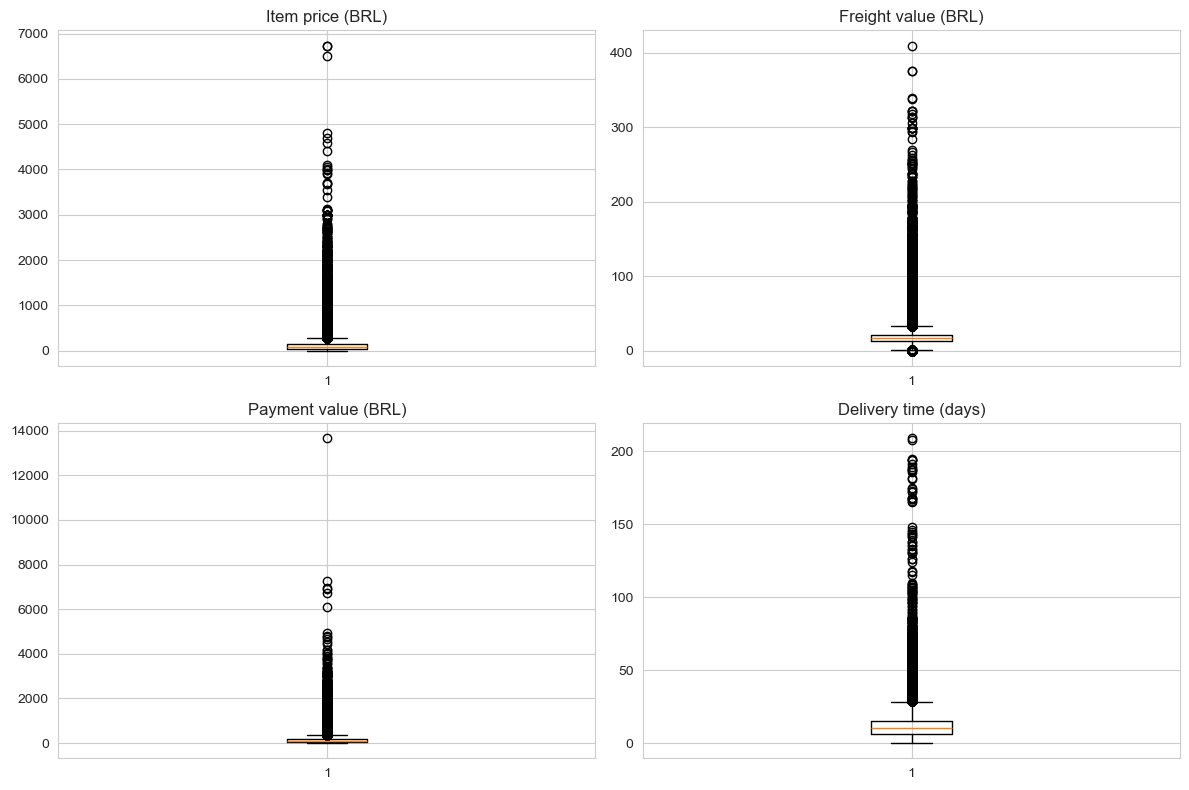

In [31]:
# Visual check
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0, 0].boxplot(order_items_clean["price"].dropna())
axes[0, 0].set_title("Item price (BRL)")

axes[0, 1].boxplot(order_items_clean["freight_value"].dropna())
axes[0, 1].set_title("Freight value (BRL)")

axes[1, 0].boxplot(order_payments_clean["payment_value"].dropna())
axes[1, 0].set_title("Payment value (BRL)")

axes[1, 1].boxplot(delivered_orders["delivery_days"].dropna())
axes[1, 1].set_title("Delivery time (days)")

plt.tight_layout()
plt.savefig(FIG_DIR / "14_outliers_boxplots.png")
plt.show()

#### Decision for each column

| Column | Are the outliers real? | Decision |
|---|---|---|
| `price` | **Yes** — expensive products really exist | **Keep.** Deleting them would understate revenue |
| `freight_value` | **Yes** — heavy/bulky items cost more to ship | **Keep.** Same reason |
| `payment_value` | **Yes** — a single order can really be worth 13,000 BRL | **Keep.** It is a real sale |
| `payment_installments` | **Yes** — up to 24 instalments is allowed by the business | **Keep** |
| `product_weight_g` | **Yes** — furniture and large items are heavy | **Keep** |

## Section 5 : Fill missing product categories

In [34]:
products_clean["product_category_name"] = products_clean["product_category_name"].fillna("unknown")

print("Missing category names after filling :",
      products_clean["product_category_name"].isnull().sum())

Missing category names after filling : 0


## Section 6 — Saving the Cleaned Data

In [35]:
orders_clean.to_csv(PROCESSED_DIR / "orders_clean.csv", index=False)
customers_clean.to_csv(PROCESSED_DIR / "customers_clean.csv", index=False)
order_items_clean.to_csv(PROCESSED_DIR / "order_items_clean.csv", index=False)
order_payments_clean.to_csv(PROCESSED_DIR / "order_payments_clean.csv", index=False)
order_reviews_clean.to_csv(PROCESSED_DIR / "order_reviews_clean.csv", index=False)
products_clean.to_csv(PROCESSED_DIR / "products_clean.csv", index=False)
sellers_clean.to_csv(PROCESSED_DIR / "sellers_clean.csv", index=False)
geolocation_clean.to_csv(PROCESSED_DIR / "geolocation_clean.csv", index=False)
category_translation_clean.to_csv(PROCESSED_DIR / "category_translation_clean.csv", index=False)

print("Cleaned files saved in:", PROCESSED_DIR.resolve())
print("\nFiles now in the folder:")

for f in sorted(PROCESSED_DIR.glob("*.csv")):
    print(" -", f.name)

Cleaned files saved in: C:\Users\ENG\OneDrive\Desktop\olist_data_cleaning_eda\data\processed

Files now in the folder:
 - category_translation_clean.csv
 - customers_clean.csv
 - geolocation_clean.csv
 - order_items_clean.csv
 - order_payments_clean.csv
 - order_reviews_clean.csv
 - orders_clean.csv
 - products_clean.csv
 - sellers_clean.csv
